# Biogeophysical and hydrological processes behind the forcing

Surface energy, snow/albedo and water-cycle responses that sit under the Ghan terms (`radiative_forcing.ipynb`).
Plotting code: `boreal_forest_expansion.plotting.forcing_maps`. Same contrast grids as `bvoc-soa-cloud-interactions.ipynb` (sets LCC-CTRL, LCC-fBVOC, fBVOC-CTRL; (rows = contrasts, columns = variables, own colour bar per panel).

- Hydrology comes from the new CLM category **HYDRO** (`QRUNOFF, QSNOMELT, TWS, RAIN, SNOW, …`; `postprocess/variables.py`), postprocessed on 2026-10-25 from the same runs as the other files.
- CAM fields (FSDS, PRECT, LHFLX, SHFLX, TS, CLDLOW) are grid-box values incl. ocean; CLM fields are land only (ocean = blank).

**Data and caveats (read before interpreting)**
- Input: monthly postprocessed files `data/processed-data/postprocessing/[alias]_[atm|lnd]_[CATEGORY]_2001-2009.nc` (first 12 months dropped as spin-up).
  Runs: CTRL `…nudg_ctrl_…-20260925`, LCC `…nudg_lcc_…-20261005`, fBVOC = the ISOP+MTERP-only runs `-20261008` (PD) / `-20261009` (FUT).
- **Provisional:** CTRL `-20260925` is superseded by `-20261023`; everything here is redone on the 2001–2014 set.
- CTRL and LCC have different land spin-ups (LCC: extra 100-yr land-only BGC spin-up) → LCC − CTRL contains a spin-up offset (large in FUT).
- `LCC_FUT − CTRL_PD` = LCC **plus** the whole 2100 background change (SST, GHG, CO₂, emissions): dominated by climate change.
- `LCC_FUT − LCC_FUT_fBVOC`: fBVOC_FUT uses CTRL_PD emissions → mixes the climate-driven emission change with the LCC effect; **not** a forest-expansion-only BVOC effect.
- fBVOC runs lack all non-ISOP/MTERP MEGAN compounds (no `MEG_*`), so LCC − fBVOC is not ISOP+MTERP only.
- Maps: mean of the 9 paired yearly differences. **Grey `/////` hatching = NOT significant** (paired t-test, Benjamini–Hochberg FDR α = 0.10 over the drawn cells ≥45°N).
  Text under each panel: area-weighted mean ≥45°N ± 95 % t-interval across years (land-only fields: land mean).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import matplotlib.pyplot as plt
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
START_YEAR, END_YEAR = 2001, 2009
common = dict(start_year=START_YEAR, end_year=END_YEAR, extent_lat=45, mean_lat_min=45, save=True)
print("Figures ->", fm.FIGURE_DIR)
print(fm.BVOC_PAIRS)

for alias in sorted({a for rows in fm.contrast_sets().values() for p in rows for a in p}):
    path = fm.filename(alias, "HYDRO", START_YEAR, END_YEAR, "lnd")
    print(path.name, "✓" if path.exists() else "MISSING")

Figures -> /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures
{'PD': {'lcc': 'LCC_PD', 'fbvoc': 'LCC_PD_fBVOC', 'ctrl': 'CTRL_PD'}, 'FUT': {'lcc': 'LCC_FUT', 'fbvoc': 'LCC_FUT_fBVOC', 'ctrl': 'CTRL_FUT'}}
CTRL_FUT_lnd_HYDRO_2001-2009.nc ✓
CTRL_PD_lnd_HYDRO_2001-2009.nc ✓
LCC_FUT_lnd_HYDRO_2001-2009.nc ✓
LCC_FUT_fBVOC_lnd_HYDRO_2001-2009.nc ✓
LCC_PD_lnd_HYDRO_2001-2009.nc ✓
LCC_PD_fBVOC_lnd_HYDRO_2001-2009.nc ✓


## 1. Hydrology and surface fluxes
FSDS, precipitation (CAM PRECC + PRECL), ET, total runoff, snowmelt, total water storage, top-10 cm soil water, latent and sensible heat, low cloud.

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_hydro_LCC-CTRL_2001_2009.png


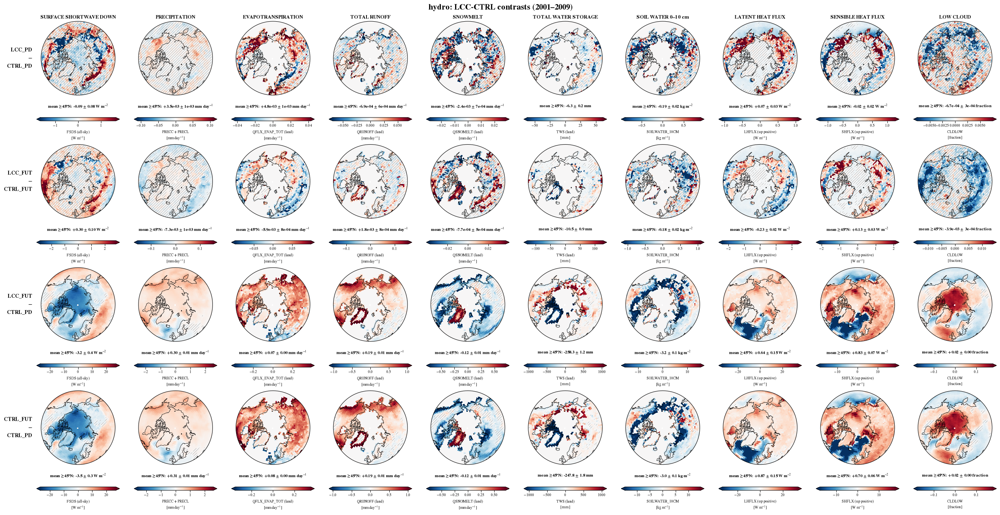

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_hydro_LCC-fBVOC_2001_2009.png


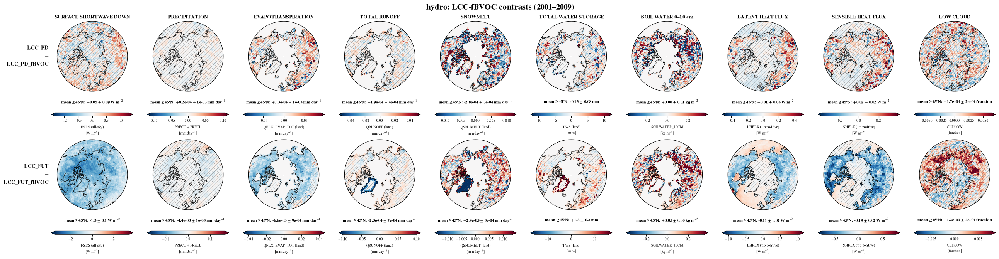

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_hydro_fBVOC-CTRL_2001_2009.png


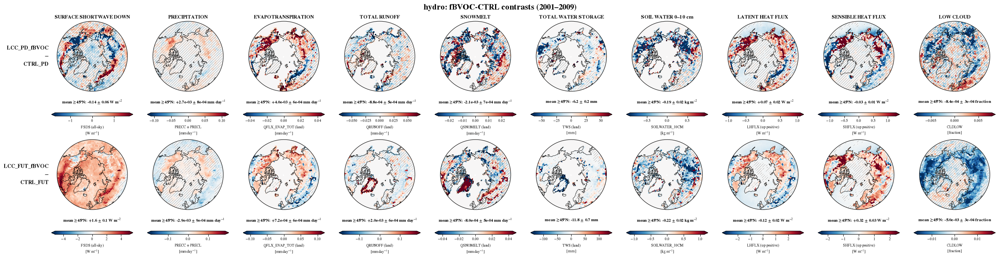

In [2]:
for cset in fm.contrast_sets():
    fig, axes = fm.make_contrast_grid_figure(cset, fm.HYDRO_PANELS, "hydro", start_year=START_YEAR, end_year=END_YEAR)
    plt.show(); plt.close(fig)

## 2. Snow and surface albedo
Snow cover (annual and MAM), snow water equivalent, snow persistence (days), canopy snow, MAM surface albedo (CLM FSR / FSDS, ratio of month-weighted means), LAI.
The MAM albedo is the spring snow-masking signal behind the SW clear-clean term.

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_snow_albedo_LCC-CTRL_2001_2009.png


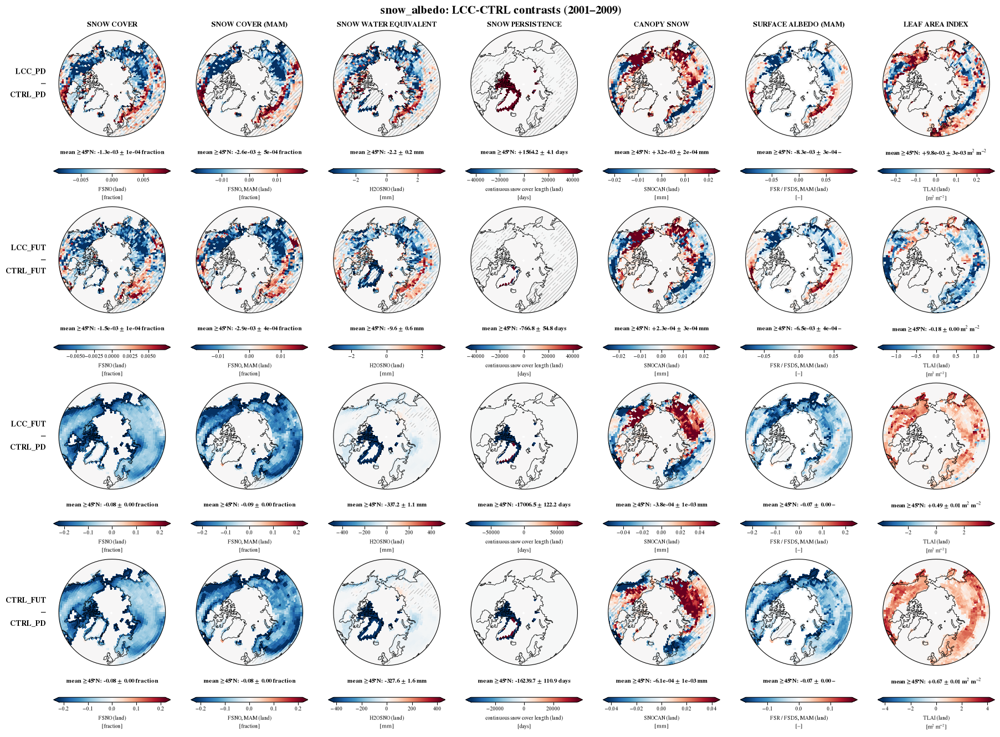

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_snow_albedo_LCC-fBVOC_2001_2009.png


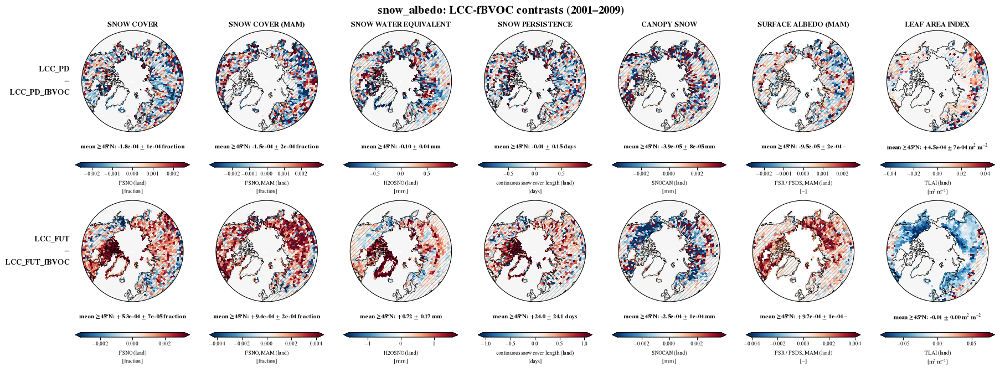

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_snow_albedo_fBVOC-CTRL_2001_2009.png


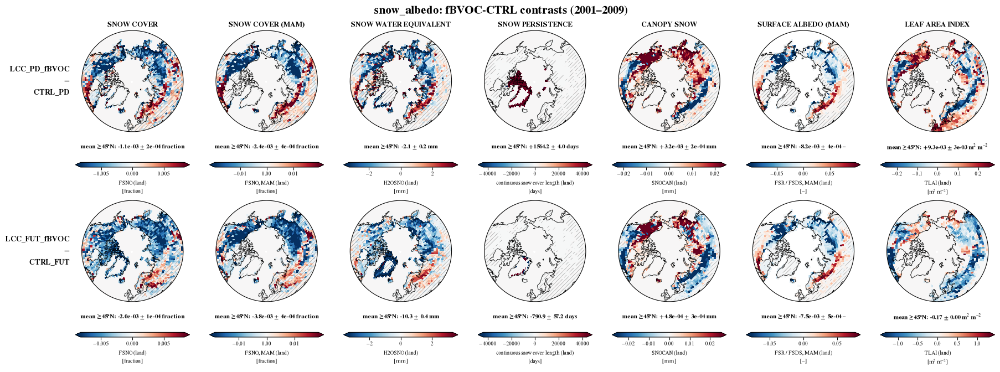

In [3]:
for cset in fm.contrast_sets():
    fig, axes = fm.make_contrast_grid_figure(cset, fm.SNOW_ALBEDO_PANELS, "snow_albedo", start_year=START_YEAR, end_year=END_YEAR)
    plt.show(); plt.close(fig)

## 3. Surface energy partition
Net surface SW, downwelling LW, surface and 2 m temperature, latent and sensible heat, Bowen ratio (SHFLX / LHFLX as a ratio of annual means, masked where |LHFLX| < 5 W m⁻²).
FLDS and TS link to the LW clear-clean term (warmer, moister boundary layer).

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_surface_energy_LCC-CTRL_2001_2009.png


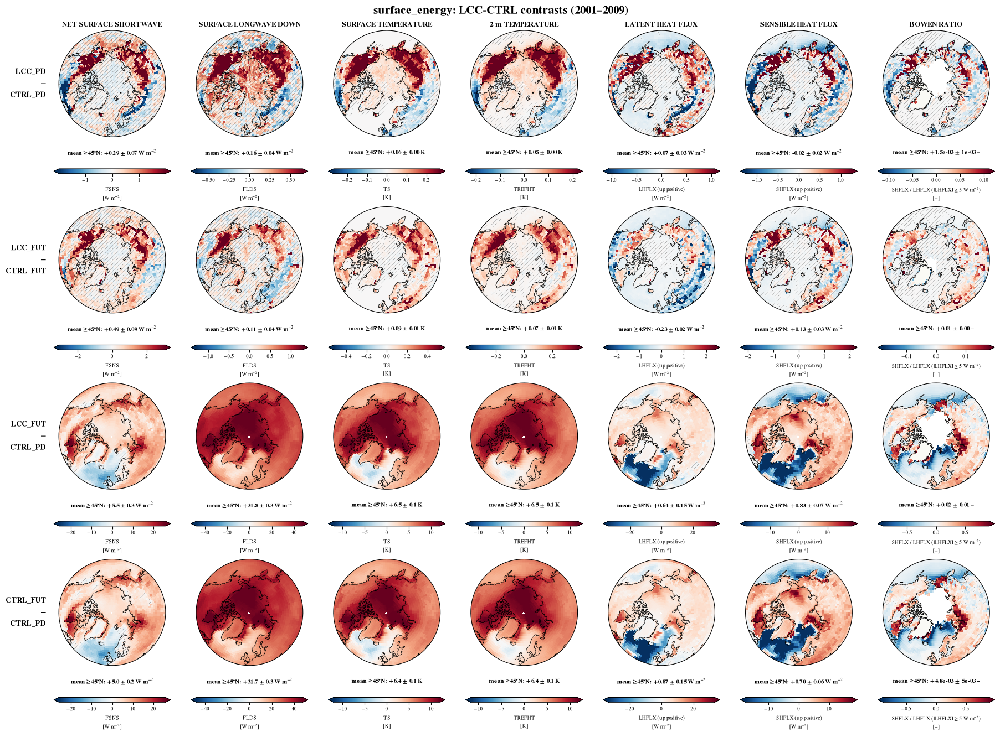

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_surface_energy_LCC-fBVOC_2001_2009.png


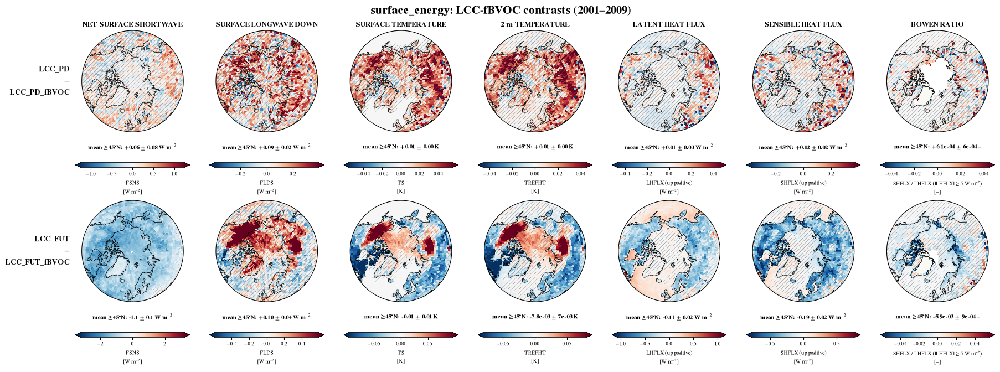

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_surface_energy_fBVOC-CTRL_2001_2009.png


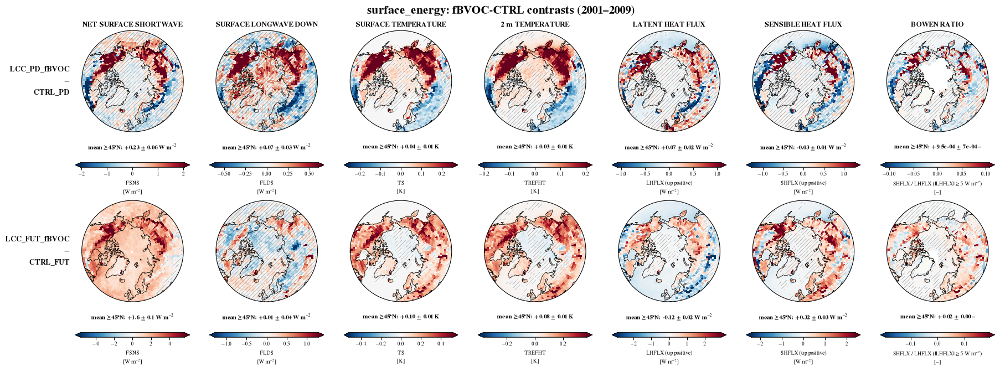

In [4]:
for cset in fm.contrast_sets():
    fig, axes = fm.make_contrast_grid_figure(cset, fm.SURFACE_ENERGY_PANELS, "surface_energy", start_year=START_YEAR, end_year=END_YEAR)
    plt.show(); plt.close(fig)

## 4. FSDS split
All-sky FSDS, clear-sky FSDSC, cloud part FSDS − FSDSC, aerosol part FSDS − FSDS_DRF, clear-clean FSDSCDRF.
These are diagnostic differences from the extra radiation calls, **not** an exact additive decomposition of FSDS.

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_fsds_split_LCC-CTRL_2001_2009.png


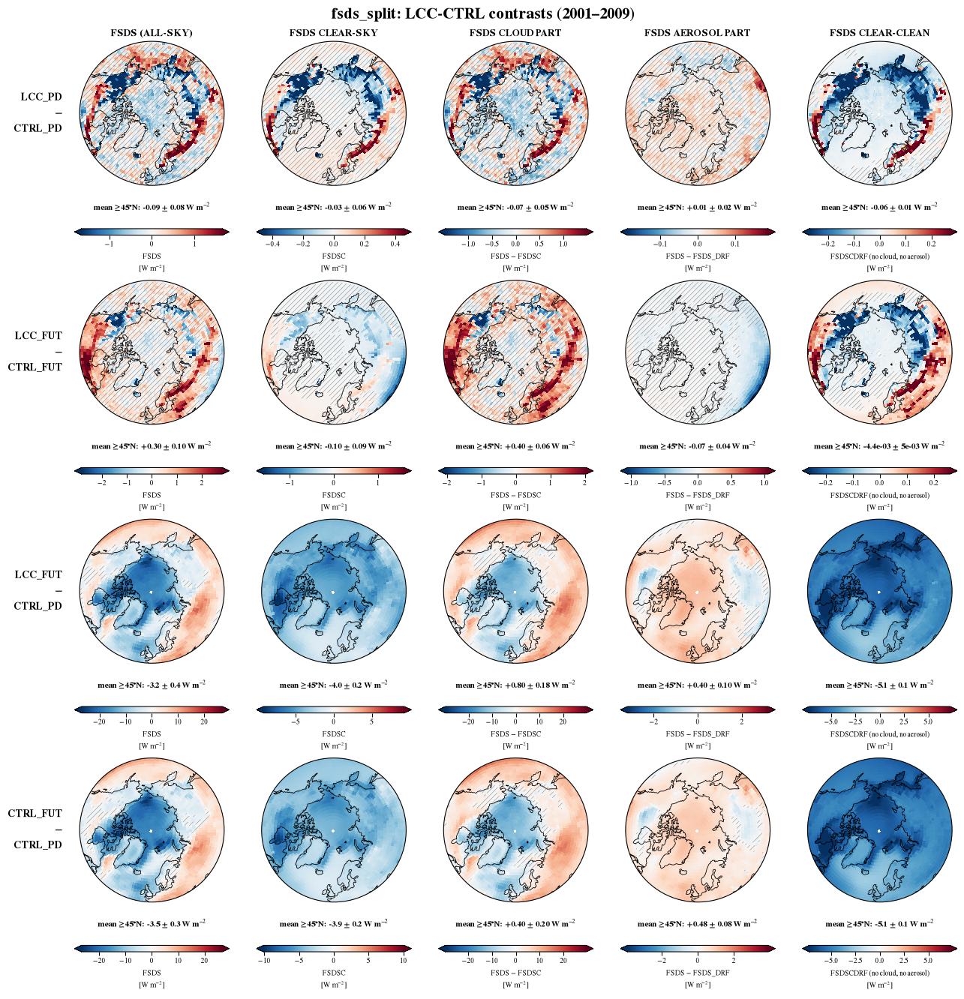

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_fsds_split_LCC-fBVOC_2001_2009.png


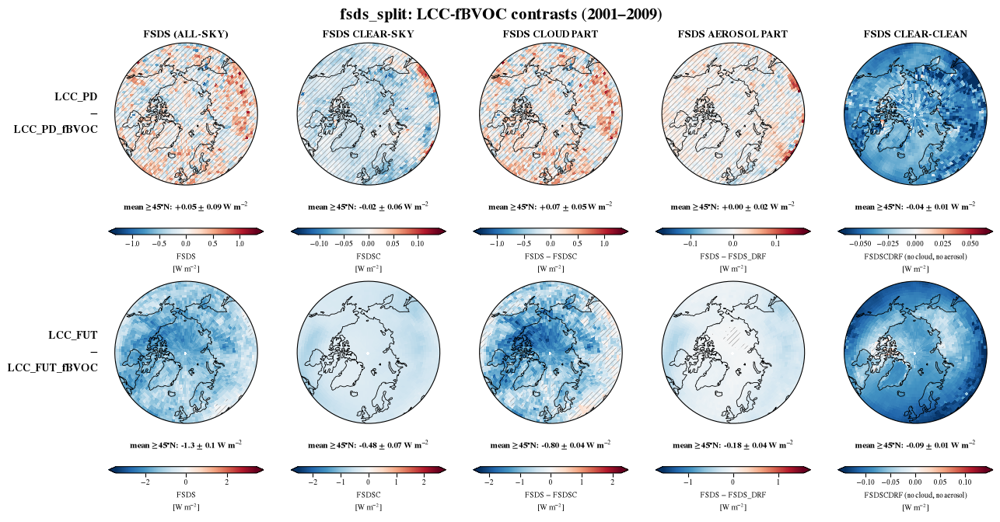

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_fsds_split_fBVOC-CTRL_2001_2009.png


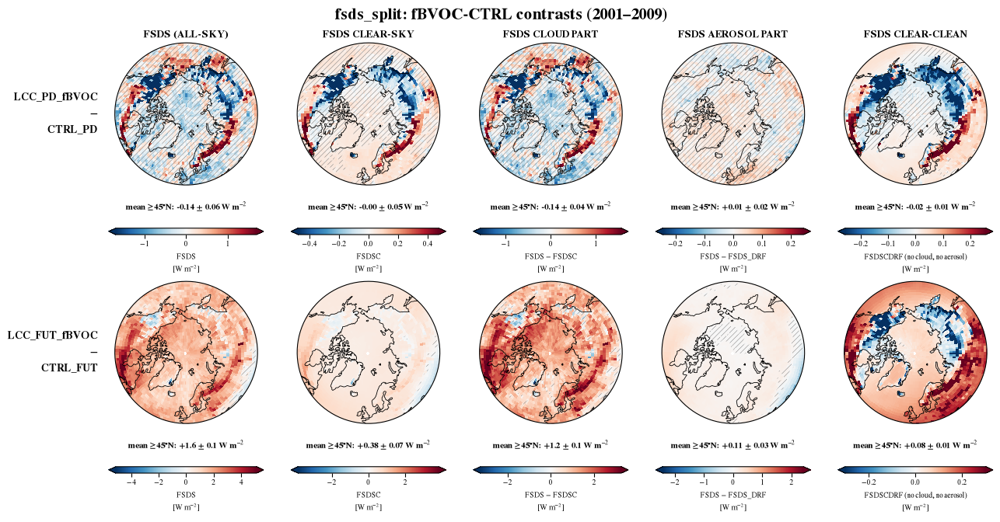

In [5]:
for cset in fm.contrast_sets():
    fig, axes = fm.make_contrast_grid_figure(cset, fm.FSDS_SPLIT_PANELS, "fsds_split", start_year=START_YEAR, end_year=END_YEAR)
    plt.show(); plt.close(fig)

## 5. Land water budget: P − ET − R_liq − R_ice − ΔTWS
All terms from CLM (same land basis), mm yr⁻¹: P = RAIN + SNOW, ET = QFLX_EVAP_TOT, R_liq = QRUNOFF_TO_COUPLER, R_ice = QRUNOFF_ICE_TO_COUPLER (solid runoff from snow capping, mostly glaciers/Greenland), ΔTWS = TWS(Dec y) − TWS(Dec y−1).
ΔTWS needs the previous December, so the budget covers **2002–2009 (8 paired years)**.
Regions: LCC-modified cells (`diagnostics/check-simulation-equilibrium/lcc-modified-cells/modified_cells.nc`) and unmodified land ≥45°N; weights = area × landfrac.
The residual of each run should be ≈ 0 (budget check).

Why the coupler runoff (2026-10-25): with liquid `QRUNOFF` only, unmodified land ≥45°N left +27.7 mm yr⁻¹ unclosed in CTRL_PD (≈5 % of P). Adding the ice runoff and the land-use corrections closes every run and region to < 1 mm yr⁻¹ (CTRL_PD: +0.10 modified, −0.52 unmodified; LCC_FUT: −0.24 / −0.65).

In [6]:
import pandas as pd
pd.set_option("display.width", 200, "display.max_rows", 200)

table = fm.water_budget_table(START_YEAR, END_YEAR)
out = fm.REPO_DIR / "results" / "tables" / f"water_budget_{START_YEAR}_{END_YEAR}.csv"
table.to_csv(out, index=False)
print("Saved", out)
table.round(2)

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/tables/water_budget_2001_2009.csv


,contrast_set,contrast,region,term,case1,case2,diff,ci95,n_years,years
0,LCC-CTRL,LCC_PD − CTRL_PD,modified cells,P,548.86,546.07,2.79,0.92,8,2002–2009
1,LCC-CTRL,LCC_PD − CTRL_PD,modified cells,ET,225.91,222.91,3.00,0.66,8,2002–2009
2,LCC-CTRL,LCC_PD − CTRL_PD,modified cells,R_liq,320.75,320.98,-0.23,0.51,8,2002–2009
3,LCC-CTRL,LCC_PD − CTRL_PD,modified cells,R_ice,-1.21,-1.16,-0.05,0.02,8,2002–2009
4,LCC-CTRL,LCC_PD − CTRL_PD,modified cells,dTWS,3.33,3.23,0.10,0.50,8,2002–2009
5,LCC-CTRL,LCC_PD − CTRL_PD,modified cells,residual,0.08,0.10,-0.02,0.14,8,2002–2009
6,LCC-CTRL,LCC_PD − CTRL_PD,unmodified land ≥45°N,P,558.19,556.54,1.66,0.60,8,2002–2009
7,LCC-CTRL,LCC_PD − CTRL_PD,unmodified land ≥45°N,ET,325.76,323.45,2.31,0.76,8,2002–2009
8,LCC-CTRL,LCC_PD − CTRL_PD,unmodified land ≥45°N,R_liq,206.75,207.67,-0.92,0.42,8,2002–2009
9,LCC-CTRL,LCC_PD − CTRL_PD,unmodified land ≥45°N,R_ice,28.03,28.25,-0.22,0.09,8,2002–2009


In [7]:
# Residual of each run on its own (budget check), mm/yr
table[table.term == "residual"][["contrast", "region", "case1", "case2"]].round(2)

,contrast,region,case1,case2
5,LCC_PD − CTRL_PD,modified cells,0.08,0.10
11,LCC_PD − CTRL_PD,unmodified land ≥45°N,-0.52,-0.52
17,LCC_FUT − CTRL_FUT,modified cells,-0.24,-0.20
23,LCC_FUT − CTRL_FUT,unmodified land ≥45°N,-0.65,-0.64
29,LCC_FUT − CTRL_PD,modified cells,-0.24,0.10
35,LCC_FUT − CTRL_PD,unmodified land ≥45°N,-0.65,-0.52
41,CTRL_FUT − CTRL_PD,modified cells,-0.20,0.10
47,CTRL_FUT − CTRL_PD,unmodified land ≥45°N,-0.64,-0.52
53,LCC_PD − LCC_PD_fBVOC,modified cells,0.08,0.07
59,LCC_PD − LCC_PD_fBVOC,unmodified land ≥45°N,-0.52,-0.51


findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/water_budget_LCC-CTRL_2001_2009.png


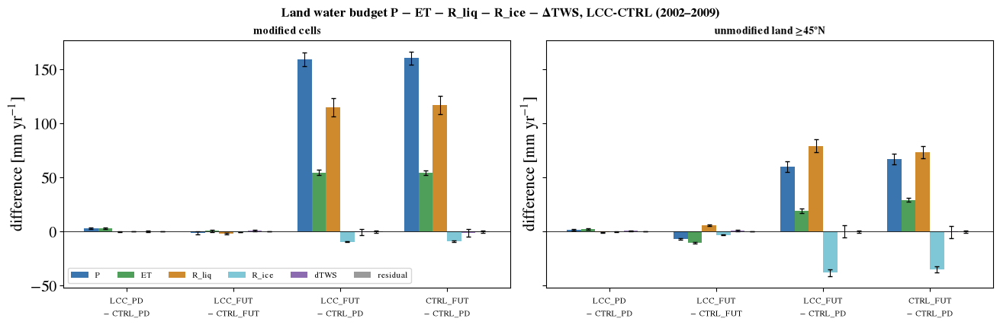

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/water_budget_LCC-fBVOC_2001_2009.png


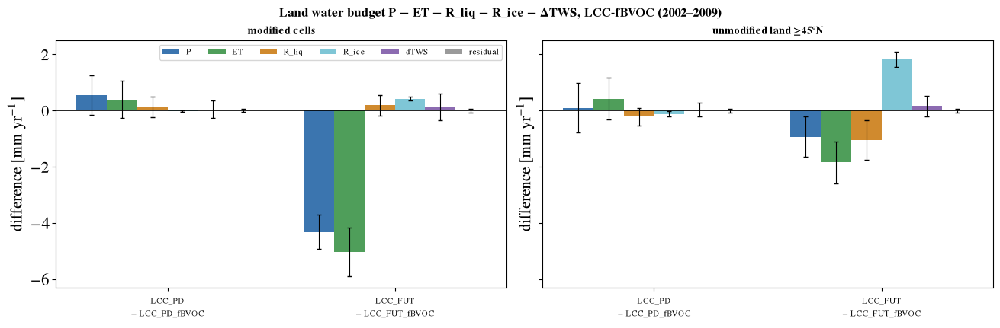

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/water_budget_fBVOC-CTRL_2001_2009.png


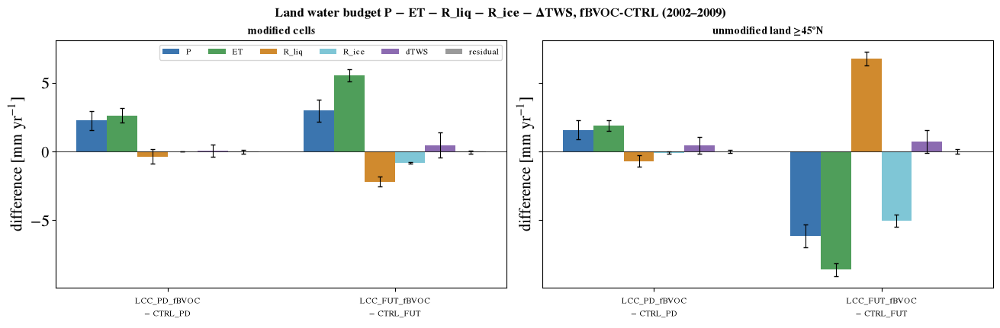

In [8]:
for cset in fm.contrast_sets():
    fig, axes = fm.make_water_budget_figure(table, cset, start_year=START_YEAR, end_year=END_YEAR)
    plt.show(); plt.close(fig)